### Mohammed Omar Mkhallati
### Data Science and its Applications
### Monday, September 28, 2026
### Graded Assessment: Project 1
### Source : https://archive.ics.uci.edu/dataset/2/adult

#### Import Statements

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
import ssl

pd.set_option('display.max_columns', None) # This Line Makes Pandas Display All Columns
plt.rcParams['figure.figsize'] = (7, 4) # This Line Sets The Default Figure Size For Plots

#### Loading the Needed Datasets

In [2]:
# adult.data has no Headers, so we will Define the Headers Manually as they are Defined in adult.names
columns = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']

# Here, we Define the URLs for the Training and Testing Files from my GitHub
training_data_url = 'https://raw.githubusercontent.com/omarmkhallati/AAI614_Mkhallati/main/Project%201/adult.data'
testing_data_url = 'https://raw.githubusercontent.com/omarmkhallati/AAI614_Mkhallati/main/Project%201/adult.test'

# Here, we Read the Training Data and we Specify the Headers, Separator, and Assign '?' as NaN Values
df_train = pd.read_csv(training_data_url, names=columns, sep=r',\s*', engine='python', na_values='?')
print(df_train.shape)
df_train.head()

(32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


#### Data Exploration - 1. Column Data Types

##### Here, we Need to Confirm that the Training Data Datatypes have been Read Correctly, and Allign with the Expected Values from `adult.names`

In [3]:
df_train.dtypes

age                int64
workclass         object
fnlwgt             int64
education         object
education_num      int64
marital_status    object
occupation        object
relationship      object
race              object
sex               object
capital_gain       int64
capital_loss       int64
hours_per_week     int64
native_country    object
income            object
dtype: object

In [4]:
# We get the Expected Types from adult.names and we will Compare them with the Actual Types in the DataFrame
expected_type = {'age': 'continuous', 'workclass': 'categorical', 'fnlwgt': 'continuous',
    'education': 'categorical', 'education_num': 'continuous', 'marital_status': 'categorical',
    'occupation': 'categorical', 'relationship': 'categorical', 'race': 'categorical',
    'sex': 'categorical', 'capital_gain': 'continuous', 'capital_loss': 'continuous',
    'hours_per_week': 'continuous', 'native_country': 'categorical', 'income': 'categorical'
}

summary = pd.DataFrame({'Expected Type': expected_type, 'Actual Type': df_train.dtypes})

summary

,Expected Type,Actual Type
age,continuous,int64
workclass,categorical,object
fnlwgt,continuous,int64
education,categorical,object
education_num,continuous,int64
marital_status,categorical,object
occupation,categorical,object
relationship,categorical,object
race,categorical,object
sex,categorical,object


##### Now, we Verified that the Columns Datatypes are Correct

#### Data Exploration - 2. Missing Values

##### We Already Replaced the `?` with `np.nan` when Importing the Dataset. Below, we will just Count the Missing Values

In [5]:
missing_values = df_train.isna().sum()
missing_values[missing_values > 0].sort_values(ascending=False)

occupation        1843
workclass         1836
native_country     583
dtype: int64

In [6]:
print ("Total Number of Rows in the Training Data: ", len(df_train))
print ("Total Number of Rows with Missing Values in the Training Data : ", df_train.isna().any(axis=1).sum())

Total Number of Rows in the Training Data:  32561
Total Number of Rows with Missing Values in the Training Data :  2399


##### Missing Values Show in `occupation`, `workclass`, and `native_country`

#### Data Exploration - 3. `capital_gain` and `capital_loss` Ditributions

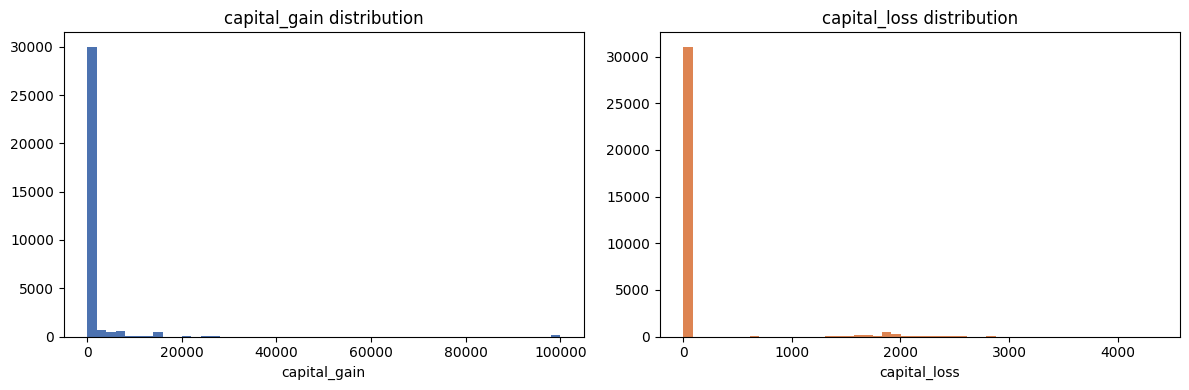

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df_train['capital_gain'], bins=50, color='#4C72B0')
ax[0].set_title('capital_gain distribution')
ax[0].set_xlabel('capital_gain')
ax[1].hist(df_train['capital_loss'], bins=50, color='#DD8452')
ax[1].set_title('capital_loss distribution')
ax[1].set_xlabel('capital_loss')
plt.tight_layout()
plt.show()

In [8]:
print ("People with Capital Gain = 0 : ", (df_train['capital_gain'] == 0).mean().round(4) * 100, "%")
print ("People with Capital Loss = 0 : ", (df_train['capital_loss'] == 0).mean().round(4) * 100, "%")
print (df_train[['capital_gain', 'capital_loss']].describe())

People with Capital Gain = 0 :  91.67 %
People with Capital Loss = 0 :  95.33 %
       capital_gain  capital_loss
count  32561.000000  32561.000000
mean    1077.648844     87.303830
std     7385.292085    402.960219
min        0.000000      0.000000
25%        0.000000      0.000000
50%        0.000000      0.000000
75%        0.000000      0.000000
max    99999.000000   4356.000000


##### For `capital_gain` and `capital_loss`, the Columns are Almost Entirely `0`. 91.67% for `capital_gain` and 95.33% for `capital_loss`. It Makes More Sense to Turn them into a Categorical Variable (none, low, high)

In [9]:
def turn_to_categorical (x) :
    if x == 0 :
        return 'none'
    elif x < 5000 :
        return 'low'
    else :
        return 'high'

df_train['capital_gain_category'] = df_train['capital_gain'].apply(turn_to_categorical)
df_train['capital_loss_category'] = df_train['capital_loss'].apply(turn_to_categorical)

print (df_train['capital_gain_category'].value_counts())
print ()
print (df_train['capital_loss_category'].value_counts())

capital_gain_category
none    29849
high     1648
low      1064
Name: count, dtype: int64

capital_loss_category
none    31042
low      1519
Name: count, dtype: int64


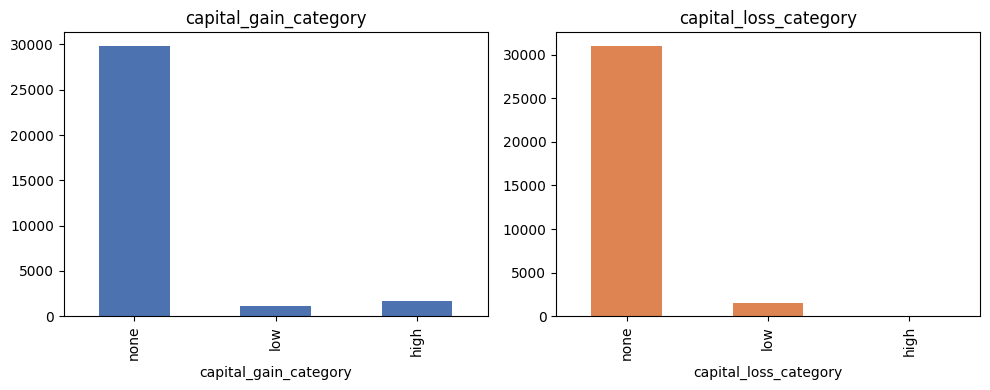

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df_train['capital_gain_category'].value_counts().reindex(['none', 'low', 'high']).plot(kind='bar', ax=ax[0], color='#4C72B0')
ax[0].set_title('capital_gain_category')
df_train['capital_loss_category'].value_counts().reindex(['none', 'low', 'high']).plot(kind='bar', ax=ax[1], color='#DD8452')
ax[1].set_title('capital_loss_category')
plt.tight_layout()
plt.show()

#### Data Exploration - 4. `fnlwgt` Sampling Weight Distribution

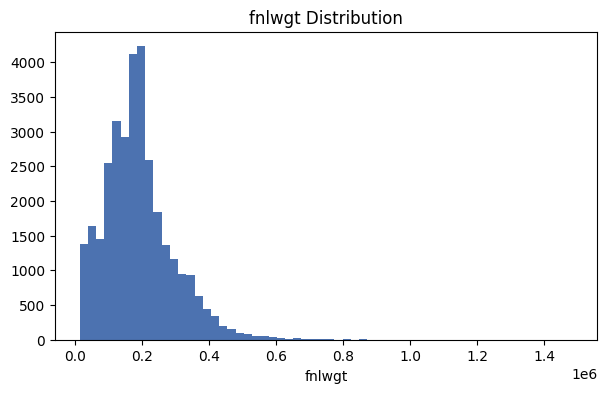

count    3.256100e+04
mean     1.897784e+05
std      1.055500e+05
min      1.228500e+04
25%      1.178270e+05
50%      1.783560e+05
75%      2.370510e+05
max      1.484705e+06
Name: fnlwgt, dtype: float64
Skewness:  1.447


In [11]:
fig, ax = plt.subplots()
ax.hist(df_train['fnlwgt'], bins=60, color='#4C72B0')
ax.set_title('fnlwgt Distribution')
ax.set_xlabel('fnlwgt')
plt.show()

print (df_train['fnlwgt'].describe())
print ('Skewness: ', df_train['fnlwgt'].skew().round(4))

##### We Notice that `fnlwgt` is not symmetric. It is Right-Skewed

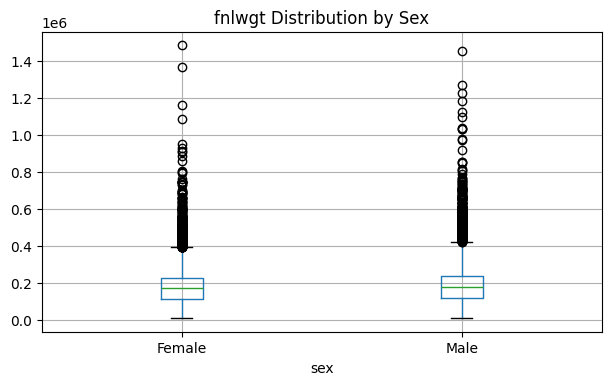

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
Female,10771.0,185746.311206,102986.078821,12285.0,117363.00,176077.0,228331.50,1484705.0
Male,21790.0,191771.449013,106740.702676,13769.0,118200.75,180140.0,241146.25,1455435.0


In [12]:
fig, ax = plt.subplots()
df_train.boxplot(column='fnlwgt', by='sex', ax=ax)
plt.suptitle('')  # Remove the default title to avoid overlap
ax.set_title('fnlwgt Distribution by Sex')
plt.show()

df_train.groupby('sex')['fnlwgt'].describe()

##### Men and Women Have Similar `fnlwgt` Medians and Spread. We will Deal with the Outliers Using the IQR Method

In [13]:
# Using 3 Here Instead of 1.5 Avoids Flagging Routine Spread as an Outlier and only Catches the Genuinely Unusual Weights
q1, q3 = df_train['fnlwgt'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 3 * iqr, q3 + 3 * iqr
non_outliers = df_train[(df_train['fnlwgt'] < lower) | (df_train['fnlwgt'] > upper)].shape[0]
print(f"IQR Fence : Lower = {lower}, Upper = {upper}")
print(f"Number of Outliers: {non_outliers}")

# We Set the Values Outside the IQR Fence to NaN, and we Create a New Column for the Cleaned Data
df_train['fnlwgt_cleaned'] = df_train['fnlwgt'].where((df_train['fnlwgt'] >= lower) & (df_train['fnlwgt'] <= upper))
print('Missing after cleaning :', df_train['fnlwgt_cleaned'].isna().sum())

IQR Fence : Lower = -239845.0, Upper = 594723.0
Number of Outliers: 152
Missing after cleaning : 152


##### The Records that have an Extremely Large `fnlwgt` Value, it is set to Missing in `fnlwgt_cleaned` to Avoid Extreme Weights

#### Data Exploration - 5. Linear Regression `hours_per_week` and `sex`

In [14]:
# adult.test is the Datasets Testing Set. We will use it Here. Its First Line is a Header row ("|1x3 Cross validator") and its Income Values end with a Period (e.g. "<=50K." instead of "<=50K"), so Both Need to be Handled Before it can be Read the Same way as adult.data
df_testing = pd.read_csv(testing_data_url, names=columns, sep=r',\s*', engine='python', na_values='?', skiprows=1)
df_testing['income'] = df_testing['income'].str.rstrip('.')

print(df_testing.shape)
df_testing.head()

(16281, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [15]:
df_train['sex_male'] = df_train['sex'].map({'Male': 1, 'Female': 0})
df_testing['sex_male'] = df_testing['sex'].map({'Male': 1, 'Female': 0})

model_1 = LinearRegression().fit(df_train[['sex_male']], df_train['hours_per_week'])
model_1_train_R2 = model_1.score(df_train[['sex_male']], df_train['hours_per_week'])
model_1_test_R2 = model_1.score(df_testing[['sex_male']], df_testing['hours_per_week'])

print('Model 1 : hours_per_week and sex_male')
print(f"Intercept : {model_1.intercept_:.4f}")
print(f"sex_male Coefficient : {model_1.coef_[0]:.4f}")
print(f"R-squared (Train) : {model_1_train_R2:.4f}")
print(f"R-squared (Test) :  {model_1_test_R2:.4f}")

Model 1 : hours_per_week and sex_male
Intercept : 36.4104
sex_male Coefficient : 6.0177
R-squared (Train) : 0.0526
R-squared (Test) :  0.0516


##### The Intercept is the Average `hours_per_week` for Women. The `sex_male` Coefficient is how Many Hours Men Average on top of That. Since the Coefficient is Positive, on Average, Men in this Sample Work More Hours Per Week Than Women. R^2 Also Holds up on the Testing Data.

#### Data Exploration - 6. Discussion

##### a) Who Works More Hours Per Week — Men or Women?

In [16]:
# Mean hours_per_week by Sex, and the Difference Between Them
means = df_train.groupby('sex')['hours_per_week'].mean()
print(means)
print(f"\nDifference (Male - Female) : {means['Male'] - means['Female']:.4f}")

sex
Female    36.410361
Male      42.428086
Name: hours_per_week, dtype: float64

Difference (Male - Female) : 6.0177


##### On Average, Men Work More Hours Per Week than Women (42.43 vs. 36.41), a Difference of 6.02 Hours that Matches the `sex_male` Coefficient from Model 1

##### b) Controlling for `education_num` — Does the Trend Remain the Same?

In [17]:
# Model 2 : hours_per_week ~ sex_male + education_num
model_2 = LinearRegression().fit(df_train[['sex_male', 'education_num']], df_train['hours_per_week'])

print('Model 2 : hours_per_week and sex_male + education_num')
print(f"sex_male Coefficient : {model_2.coef_[0]:.4f}")
print(f"education_num Coefficient : {model_2.coef_[1]:.4f}")

print(f"\nsex_male Coefficient — Model 1 (No Control) : {model_1.coef_[0]:.4f}")
print(f"sex_male Coefficient — Model 2 (Controlling for education_num) : {model_2.coef_[0]:.4f}")

Model 2 : hours_per_week and sex_male + education_num
sex_male Coefficient : 5.9709
education_num Coefficient : 0.6975

sex_male Coefficient — Model 1 (No Control) : 6.0177
sex_male Coefficient — Model 2 (Controlling for education_num) : 5.9709


##### The `sex_male` Coefficient Barely Moves After Controlling for `education_num` (6.02 to 5.97), so the Hours Gap Between Men and Women is not Explained by Education. The `education_num` Coefficient of 0.70 Suggests it has its own Relationship with `hours_per_week`, which we Test Formally for Significance in the Correlation Section Below (r = 0.148, p = 4.24e-159), Confirming it is a Significant Predictor

##### c) Adding `gross_income_group` and Comparing the 1-, 2-, and 3-Variable Models

In [18]:
# gross_income_group : Binary Variable, 1 if Income > 50K, 0 Otherwise (<=50K)
df_train['gross_income_group'] = (df_train['income'] == '>50K').astype(int)
df_testing['gross_income_group'] = (df_testing['income'] == '>50K').astype(int)

# Model 3 : hours_per_week ~ sex_male + education_num + gross_income_group
model_3 = LinearRegression().fit(df_train[['sex_male', 'education_num', 'gross_income_group']], df_train['hours_per_week'])

print('Model 3 : hours_per_week and sex_male + education_num + gross_income_group')
print(f"sex_male Coefficient : {model_3.coef_[0]:.4f}")
print(f"education_num Coefficient : {model_3.coef_[1]:.4f}")
print(f"gross_income_group Coefficient : {model_3.coef_[2]:.4f}")

Model 3 : hours_per_week and sex_male + education_num + gross_income_group
sex_male Coefficient : 5.1010
education_num Coefficient : 0.4478
gross_income_group Coefficient : 4.5175


In [19]:
model_comparison = pd.DataFrame({
    'Model': ['1. sex_male', '2. + education_num', '3. + gross_income_group'],
    'R-squared': [
        model_1.score(df_train[['sex_male']], df_train['hours_per_week']),
        model_2.score(df_train[['sex_male', 'education_num']], df_train['hours_per_week']),
        model_3.score(df_train[['sex_male', 'education_num', 'gross_income_group']], df_train['hours_per_week']),
    ],
})

model_comparison

,Model,R-squared
0,1. sex_male,0.052583
1,2. + education_num,0.073700
2,3. + gross_income_group,0.094325


##### R-squared Rises with Each Added Variable (0.053, 0.074, 0.094 for Models 1, 2, and 3), but R-squared Alone is not a Fair Way to Compare Models with Different Numbers of Variables, Since it Mechanically Increases Whenever a Predictor is Added, even a Weak one. Adjusted R-squared, which Penalizes Extra Predictors, is the More Appropriate Statistic for Deciding Between Nested Models like These. Given the Steady Rise in Fit and the Sizeable `gross_income_group` Coefficient (4.52 Extra Hours per Week), the 3-Variable Model is Preferred

#### Correlation Between `age`, `education_num`, and `hours_per_week`

##### 1. Correlation Matrix : `age`, `education_num`, `hours_per_week`

In [20]:
corr_vars = ['age', 'education_num', 'hours_per_week']
corr_matrix = df_train[corr_vars].corr()
corr_matrix

,age,education_num,hours_per_week
age,1.000000,0.036527,0.068756
education_num,0.036527,1.000000,0.148123
hours_per_week,0.068756,0.148123,1.000000


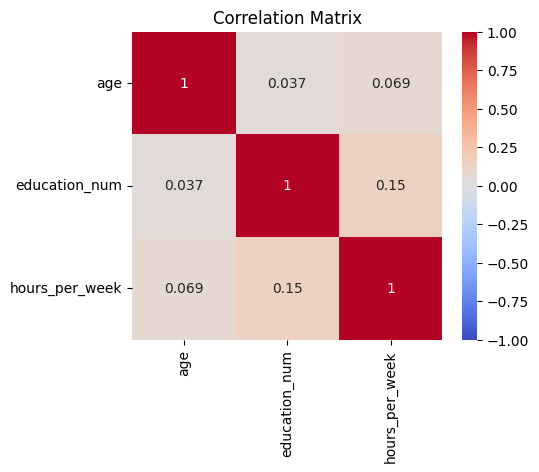

In [21]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation Matrix')
plt.show()

##### All Three Pairwise Correlations are Weak. `education_num` and `hours_per_week` are the Strongest Pair at r = 0.148, Followed by `age` and `hours_per_week` at r = 0.069, and `age` and `education_num` at r = 0.037. None Show a Strong Relationship, though `education_num` and `hours_per_week` Come Closest to a Real Association

##### 2. Significance Test for Pairs with |r| > 0.1

In [22]:
# Only Keep the Pairs whose Correlation Coefficient Exceeds |0.1|
var_pairs = [(corr_vars[i], corr_vars[j]) for i in range(len(corr_vars)) for j in range(i + 1, len(corr_vars))]
pairs_to_test = [(a, b) for a, b in var_pairs if abs(corr_matrix.loc[a, b]) > 0.1]

results = []
for a, b in pairs_to_test:
    r, p_value = stats.pearsonr(df_train[a], df_train[b])
    results.append({'Pair': f'{a} vs {b}', 'r': r, 'p-value': p_value})

pd.DataFrame(results)

,Pair,r,p-value
0,education_num vs hours_per_week,0.148123,4.236647e-159


##### Only `education_num` vs. `hours_per_week` Exceeds |r| = 0.1. The Pearson Test Gives r = 0.148 and p = 4.24e-159, so the Correlation is Statistically Significant. The Positive Direction (More Schooling, More Hours Worked) Matches Expectation, but the Magnitude is Weaker than one Might Assume Given how Central Education is often Treated as a Driver of Labor Supply

##### 3. `education_num` vs `age` Correlation, by Sex

In [23]:
for sex_val, group in df_train.groupby('sex'):
    r, p_value = stats.pearsonr(group['age'], group['education_num'])
    print(f"{sex_val} : r = {r:.4f}, p-value = {p_value:.4g}, n = {len(group)}")

Female : r = -0.0179, p-value = 0.06323, n = 10771
Male : r = 0.0605, p-value = 4.023e-19, n = 21790


##### For Women, r = -0.018 with p = 0.063 (not Significant). For Men, r = 0.061 with p = 4.02e-19 (Significant Despite Being Small, Due to the Larger Male Sample Size, n = 21,790). Among Men there is a Very Weak but Statistically Real Positive Relationship Between Age and Education; Among Women there is None. This is a Modest but Genuine Asymmetry, Possibly Reflecting Cohort Differences in Educational Attainment by Sex Over Time, though Both Effect Sizes are too Small to be Practically Meaningful

##### 4. Covariance Matrix : `education_num` and `hours_per_week`

In [24]:
cov_matrix = df_train[['education_num', 'hours_per_week']].cov()
cov_matrix

,education_num,hours_per_week
education_num,6.618890,4.705338
hours_per_week,4.705338,152.458995


##### `Var(education_num)` = 6.62, `Var(hours_per_week)` = 152.46, and `Cov(education_num, hours_per_week)` = 4.71. The Positive Covariance Confirms the Same Positive Direction Seen in the Correlation, but Since Covariance is Unstandardized, its Size Alone Does not Say Much About Strength. That is what the Correlation Coefficient (r = 0.148) is for; the Covariance Mainly Confirms the Sign Already Established by the Correlation